# Proyecto Melbourne Housing · Random Forest

**Random Forest** (S06): muchos árboles de decisión entrenados con muestras aleatorias; la predicción es la media de todos.

In [9]:
# Imports & configuration

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from sklearn.model_selection import train_test_split, cross_val_score, cross_validate, GridSearchCV, KFold
from sklearn.ensemble import RandomForestRegressor
from sklearn.metrics import mean_squared_error, mean_absolute_error, r2_score
from pathlib import Path
import folium
from folium.plugins import MarkerCluster
import subprocess, sys
from IPython.display import IFrame
from sklearn.model_selection import KFold


sns.set_theme(style="whitegrid")

In [2]:
# Define path for the new melbourne csv
BASE = Path.cwd().parent
CLEAN_FILE = BASE / "datasets" / "melbourne_limpio.csv"
# Create dataframe from csv
df = pd.read_csv(CLEAN_FILE)

# drop_first=True drops one category per column to avoid multicollinearity
# dtype=int gives 0/1 integer columns instead of booleans (same as the linear notebook)
df_modelo = pd.get_dummies(df, columns=["Type", "Suburb", "Method", "SellerG"], drop_first=True, dtype=int)
print(str(df_modelo.shape[0]) + "  " + str(df_modelo.shape[1]))

# Split the data into features (X) and target variable (y, the price)
X = df_modelo.drop("Price", axis=1)
y = df_modelo["Price"]

# Split into training (80%) and test (20%)
X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.2, random_state=42)

print(f"{len(df)} viviendas | {df.shape[1]} columnas")
print(f"Entrenamiento: {X_train.shape[0]} | Prueba: {X_test.shape[0]} | Variables: {X.shape[1]}")

27246  708
27246 viviendas | 15 columnas
Entrenamiento: 21796 | Prueba: 5450 | Variables: 707


## 2. Elegir la profundidad (curva de error, como en S05)

Si el error de prueba deja de bajar mientras el de entrenamiento sigue bajando, hay sobreajuste.

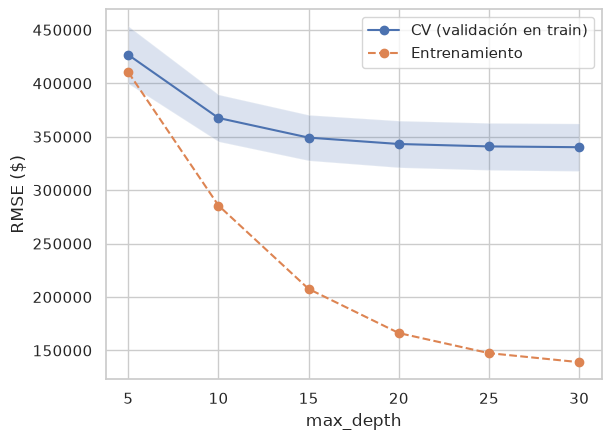

Mejor profundidad (CV en train): 30
RMSE CV en esa profundidad: 340,186 $


In [3]:
# Profundidades a probar
profundidades = [5, 10, 15, 20, 25, 30]

kf = KFold(n_splits=5, shuffle=True, random_state=42)

# 1) CV dentro del train: para cada profundidad, 5 folds (mismo kf que el resto del notebook)
busqueda = GridSearchCV(
    RandomForestRegressor(n_estimators=100, random_state=42, n_jobs=-1),
    param_grid={"max_depth": profundidades},
    cv=kf,
    scoring="neg_root_mean_squared_error",
).fit(X_train, y_train)   # el test no se usa aquí

rmse_cv_media = -busqueda.cv_results_["mean_test_score"]
rmse_cv_desv = busqueda.cv_results_["std_test_score"]

# 2) RMSE de entrenamiento por profundidad, solo para ver el sobreajuste (sigue sin usar el test)
rmse_train = []
for d in profundidades:
    rf = RandomForestRegressor(n_estimators=100, max_depth=d, random_state=42, n_jobs=-1).fit(X_train, y_train)
    rmse_train.append(np.sqrt(mean_squared_error(y_train, rf.predict(X_train))))

# 3) Gráfica: error de CV con banda de desviación y error de train
plt.plot(profundidades, rmse_cv_media, "o-", label="CV (validación en train)")
plt.fill_between(profundidades, rmse_cv_media - rmse_cv_desv, rmse_cv_media + rmse_cv_desv, alpha=0.2)
plt.plot(profundidades, rmse_train, "o--", label="Entrenamiento")
plt.xlabel("max_depth")
plt.ylabel("RMSE ($)")
plt.legend()
plt.show()

# 4) La profundidad elegida es la de menor RMSE de CV
mejor_profundidad = busqueda.best_params_["max_depth"]
print(f"Mejor profundidad (CV en train): {mejor_profundidad}")
print(f"RMSE CV en esa profundidad: {rmse_cv_media[profundidades.index(mejor_profundidad)]:,.0f} $")

## 3. Modelo final y validación cruzada (5 folds)

In [4]:
# Final model: 300 trees, using the best max_depth found in the search above
modelo_rf = RandomForestRegressor(n_estimators=300, max_depth=mejor_profundidad, random_state=42, n_jobs=-1)
# Train on the training split only, so the test split stays unseen
modelo_rf.fit(X_train, y_train)
# Predict prices for the held-out test set
pred_test = modelo_rf.predict(X_test)

# RMSE in dollars: typical size of the prediction error, penalizing large errors more
print(f"RMSE prueba: {np.sqrt(mean_squared_error(y_test, pred_test)):,.0f} $")  # "prueba" = test
# MAE in dollars: average absolute error, easier to interpret than RMSE
print(f"MAE prueba:  {mean_absolute_error(y_test, pred_test):,.0f} $")
# R²: share of price variance explained by the model (1.0 is perfect, 0 is no better than the mean)
print(f"R² prueba:   {r2_score(y_test, pred_test):.3f}")

# Cross-validation: train and evaluate 5 times, each time holding out a different fifth of the data
# Uses the full X and y, not the single train/test split, to get a more stable estimate
r2_cv = cross_val_score(
    RandomForestRegressor(n_estimators=100, max_depth=mejor_profundidad, random_state=42, n_jobs=-1),
    X, y, cv=5, scoring="r2"
)
# R² for each fold, then the mean across folds ("en los 5 folds" = across the 5 folds)
print(f"R² en los 5 folds: {np.round(r2_cv, 3)} -> media {r2_cv.mean():.3f}")

RMSE prueba: 295,634 $
MAE prueba:  181,026 $
R² prueba:   0.778
R² en los 5 folds: [0.722 0.686 0.724 0.714 0.734] -> media 0.716


## 1.1 · Predice el precio medio de una vivienda

Precio medio real:     1,046,728 $
Precio medio predicho: 1,040,336 $


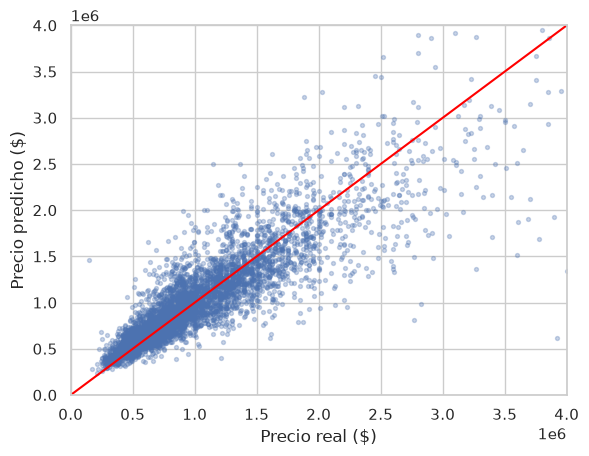

In [5]:
# Compare the average real price with the average predicted price on the test set
print(f"Precio medio real:     {y_test.mean():,.0f} $")      # "Precio medio real" = Real average price
print(f"Precio medio predicho: {pred_test.mean():,.0f} $")   # "Precio medio predicho" = Predicted average price

# Scatter plot of real vs predicted prices for each test house
# alpha=0.3 makes overlapping points visible; s=8 sets a small marker size
plt.scatter(y_test, pred_test, alpha=0.3, s=8)
# Red diagonal y = x: points on this line would be perfect predictions
plt.plot([0, 4e6], [0, 4e6], color="red")
# Fix both axes to the same range (0 to 4 million dollars) so the diagonal is comparable
plt.xlim(0, 4e6)
plt.ylim(0, 4e6)
plt.xlabel("Precio real ($)")      # "Precio real" = Real price
plt.ylabel("Precio predicho ($)")  # "Precio predicho" = Predicted price
plt.show()

## 1.2 · ¿Qué características encarecen una vivienda?

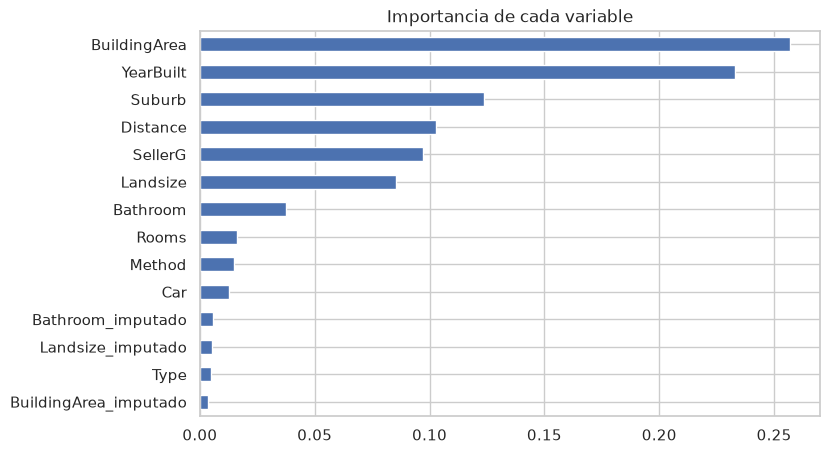

BuildingArea    0.54
Distance       -0.19
YearBuilt      -0.43
Landsize        0.05
Rooms           0.50
Price           1.00
Name: Price, dtype: float64

In [6]:
# Feature importances from the fitted random forest, one value per column of X
importancias = pd.Series(modelo_rf.feature_importances_, index=X.columns)

# One-hot encoding created columns like "Suburb_Abbotsford". Strip the suffix so each
# categorical variable is identified by its original name ("Suburb").
importancias.index = [c.split("_")[0] if c.split("_")[0] in ["Type", "Suburb", "Method", "SellerG"] else c
                      for c in importancias.index]

# Add up the importances of all dummy columns that came from the same variable,
# then sort from least to most important for the horizontal bar chart
importancias = importancias.groupby(level=0).sum().sort_values()

# Horizontal bar chart of the total importance of each original variable
importancias.plot(kind="barh", figsize=(8, 5), title="Importancia de cada variable")  # "Importancia de cada variable" = Importance of each variable
plt.show()

# Does the price go up or down with each numeric variable?
# Spearman correlation with Price: values near +1 mean the price rises with the variable,
# near -1 mean it falls, and near 0 mean there is no monotonic relationship.
df[["BuildingArea", "Distance", "YearBuilt", "Landsize", "Rooms", "Price"]].corr(method="spearman")["Price"].round(2)

## 1.3 · ¿Qué tipo de vivienda genera más beneficio?

In [7]:
# Solo viviendas de test con superficie construida real
reales = X_test.index[df.loc[X_test.index, "BuildingArea_imputado"] == 0]
datos_13 = df.loc[reales].copy()
datos_13["precio_m2"] = datos_13["Price"] / datos_13["BuildingArea"]   # indicador bruto con precio real

# Indicador bruto: mediana por tipo
res_13 = datos_13.groupby("Type").agg(n=("Price", "size"), precio_mediano=("Price", "median"),
                                      m2_mediano=("BuildingArea", "median"),
                                      bruto_precio_m2=("precio_m2", "median"))

CATEGORICAS = ["Type", "Suburb", "Method", "SellerG"]

def matriz_rf(datos):
    """Mismas columnas que en el entrenamiento (sin Price)."""
    d = pd.get_dummies(datos.drop(columns="Price"), columns=CATEGORICAS, dtype=int)
    # reindex añade con 0 las columnas que falten y elimina las de referencia
    return d.reindex(columns=X.columns, fill_value=0)

# Indicador controlado: misma vivienda, solo cambia el tipo
for tipo in res_13.index:
    cambiado = datos_13.drop(columns="precio_m2").assign(Type=tipo)
    pred = modelo_rf.predict(matriz_rf(cambiado))
    res_13.loc[tipo, "controlado_RF"] = np.median(pred / datos_13["BuildingArea"])

print("Tipo con mayor precio/m² controlado:", res_13["controlado_RF"].idxmax())
res_13.round(0)

Tipo con mayor precio/m² controlado: t


,n,precio_mediano,m2_mediano,bruto_precio_m2,controlado_RF
Type,,,,,
h,1538,1015000.0,150.0,7064.0,7404.0
t,187,840000.0,133.0,6487.0,7461.0
u,352,550500.0,76.0,7384.0,7214.0


## 1.4 · ¿Es rentable un terreno sin construir?

In [10]:
# Solo casas con superficie construida real
casas = df[(df["Type"] == "h") & (df["BuildingArea_imputado"] == 0)].copy()
EXCLUIR = ["Price", "Type", "Address", "Lat", "Lon"]
cat_14 = ["Suburb", "Method", "SellerG"]

columnas_rf = list(pd.get_dummies(casas.drop(columns=EXCLUIR, errors="ignore"),
                                  columns=cat_14, dtype=int).columns)

def matriz_rf(datos):
    d = pd.get_dummies(datos.drop(columns=EXCLUIR, errors="ignore"), columns=cat_14, dtype=int)
    return d.reindex(columns=columnas_rf, fill_value=0)

X_rf, y_rf = matriz_rf(casas), casas["Price"]

# Mismos parámetros en la CV y en el modelo final
RF_PARAMS_14 = dict(n_estimators=300, max_depth=mejor_profundidad, min_samples_leaf=2,
                    random_state=42, n_jobs=-1)

scoring = {"RMSE": "neg_root_mean_squared_error", "MAE": "neg_mean_absolute_error", "R2": "r2"}
res_14 = cross_validate(RandomForestRegressor(**RF_PARAMS_14), X_rf, y_rf, cv=kf, scoring=scoring)

rmse_14 = -res_14["test_RMSE"]
r2_14 = res_14["test_R2"]

print("=" * 52)
print("RANDOM FOREST · SOLO CASAS (validación cruzada, 5 folds)")
print("=" * 52)
print(f"Casas con superficie real : {len(casas):,}")
print(f"Variables del modelo      : {X_rf.shape[1]:,}")
print(f"Profundidad máxima        : {mejor_profundidad}")
print("-" * 52)
for i, (r2, rmse) in enumerate(zip(r2_14, rmse_14), start=1):
    print(f"Fold {i}  ·  R² = {r2:.3f}  ·  RMSE = {rmse:>10,.0f} $")
print("-" * 52)
print(f"Media    ·  R² = {r2_14.mean():.3f}  ·  RMSE = {rmse_14.mean():>10,.0f} $")
print(f"Desv.    ·  R² = {r2_14.std():.3f}  ·  RMSE = {rmse_14.std():>10,.0f} $")

# Modelo final para la sección de margen (no hay test separado en esta sección)
modelo_14 = RandomForestRegressor(**RF_PARAMS_14).fit(X_rf, y_rf)
print("\nModelo final entrenado con todas las casas.")

RANDOM FOREST · SOLO CASAS (validación cruzada, 5 folds)
Casas con superficie real : 7,889
Variables del modelo      : 576
Profundidad máxima        : 30
----------------------------------------------------
Fold 1  ·  R² = 0.747  ·  RMSE =    338,494 $
Fold 2  ·  R² = 0.739  ·  RMSE =    366,140 $
Fold 3  ·  R² = 0.740  ·  RMSE =    376,981 $
Fold 4  ·  R² = 0.752  ·  RMSE =    360,743 $
Fold 5  ·  R² = 0.682  ·  RMSE =    396,007 $
----------------------------------------------------
Media    ·  R² = 0.732  ·  RMSE =    367,673 $
Desv.    ·  R² = 0.025  ·  RMSE =     18,928 $

Modelo final entrenado con todas las casas.


### Parcelas, margenes y sensibilidad

In [11]:
# Supuestos de la sección 1.4 (no salen del dataset)
COSTE_M2 = 2_000                                      # AUD por m² construido
OTROS_COSTES = 0.15                                   # 15 % extra sobre el coste de obra
SENSIBILIDAD = [1_500, 2_000, 2_500, 3_000, 3_500]    # costes a probar

# 4. Parcelas: casas con parcela >= 200 m² y superficie construida imputada
parcelas = df[(df["Type"] == "h") & (df["BuildingArea_imputado"] == 1) &
              (df["Landsize_imputado"] == 0) & (df["Landsize"] >= 200)].copy()

# Casa nueva: la mitad de la parcela, máximo 200 m², año 2026
m2_nuevos = np.minimum(parcelas["Landsize"] * 0.5, 200)
nueva = parcelas.assign(BuildingArea=m2_nuevos, YearBuilt=2026, BuildingArea_imputado=0)
valor = modelo_14.predict(matriz_rf(nueva))

# 5. Margen para un coste de obra dado
def margen(coste_m2):
    coste_total = parcelas["Price"] + m2_nuevos * coste_m2 * (1 + OTROS_COSTES)
    return (valor - coste_total) / coste_total * 100

parcelas["margen_pct"] = margen(COSTE_M2)
print(f"{len(parcelas)} parcelas | margen mediano {parcelas['margen_pct'].median():.1f} % "
      f"| rentables (>15 %): {(parcelas['margen_pct'] > 15).mean() * 100:.1f} %")

# 6. Sensibilidad: qué pasa si la obra cuesta más o menos
sensibilidad = pd.DataFrame({
    "Coste obra (AUD/m²)": SENSIBILIDAD,
    "Margen mediano (%)": [margen(c).median() for c in SENSIBILIDAD],
    "% parcelas > 15 %": [(margen(c) > 15).mean() * 100 for c in SENSIBILIDAD],
}).round(1)
sensibilidad

6009 parcelas | margen mediano -27.5 % | rentables (>15 %): 1.2 %


,Coste obra (AUD/m²),Margen mediano (%),% parcelas > 15 %
0,1500,-21.5,3.1
1,2000,-27.5,1.2
2,2500,-32.4,0.5
3,3000,-36.7,0.3
4,3500,-40.3,0.2


In [12]:
## Margen por suburbio

# Umbral mínimo de parcelas por suburbio: con pocas, la mediana es muy inestable
MIN_PARCELAS = 30

por_suburbio = (parcelas.groupby("Suburb")["margen_pct"]
                .agg(parcelas="count", margen_mediano="median")
                .query("parcelas >= @MIN_PARCELAS")
                .sort_values("margen_mediano", ascending=False)
                .round(1))

print(f"Suburbios con al menos {MIN_PARCELAS} parcelas: {len(por_suburbio)}")

# Los 5 mejores y los 5 peores (sin duplicados si hay pocos suburbios)
pd.concat([por_suburbio.head(5), por_suburbio.tail(5)]).drop_duplicates()

Suburbios con al menos 30 parcelas: 67


,parcelas,margen_mediano
Suburb,,
Heidelberg West,46,1.1
Brunswick West,39,-7.5
West Footscray,49,-9.7
Pascoe Vale,77,-10.5
Coburg,81,-10.8
Surrey Hills,52,-38.8
Glen Waverley,46,-39.4
Hawthorn East,38,-39.4
Bentleigh,70,-39.6


## Mapa

Viviendas de prueba sobre el mapa de Melbourne: 🟢 más de un 10 % por debajo de la predicción, 🔵 ±10 %, 🔴 más de un 10 % por encima. Clic en un punto para ver sus datos.

In [14]:

# Path to the original dataset (with coordinates), relative to the parent of the working directory
BASE = Path.cwd().parent
CSV_FILE = BASE / "datasets" / "Melbourne_housing_FULL.csv"

# Load the original data with coordinates. Drop rows without a price and reset the index,
# so the row order matches the cleaned dataset.
original_csv = pd.read_csv(CSV_FILE).dropna(subset=["Price"]).reset_index(drop=True)
# Columns that identify each row, used to match the cleaned rows to the original ones
clave = ["Suburb", "Rooms", "Type", "Price", "Method", "SellerG"]
filas_original = original_csv[clave].values.tolist()

# For each row in the cleaned DataFrame, find its position in the original data.
# Both lists are in the same order, so a single forward pass is enough.
posiciones, j = [], 0
for fila in df[clave].values.tolist():
    while filas_original[j] != fila:
        j += 1
    posiciones.append(j)
    j += 1

# Copy address and coordinates from the original rows into the cleaned DataFrame
df[["Address", "Lat", "Lon"]] = original_csv.loc[posiciones, ["Address", "Lattitude", "Longtitude"]].values

# Test-set houses with coordinates, plus the predicted price and the percentage difference
# between the real price and the prediction (positive = listed above the model's estimate)
casas = df.loc[X_test.index].assign(pred=pred_test).dropna(subset=["Lat"])
casas["dif"] = (casas["Price"] - casas["pred"]) / casas["pred"] * 100

# Base map centered on Melbourne, with no default tile layer
mapa = folium.Map(location=[-37.81, 144.96], zoom_start=11, tiles=None)
# Esri tile URL template; {} is filled with the service name below
esri = "https://server.arcgisonline.com/ArcGIS/rest/services/{}/MapServer/tile/{{z}}/{{y}}/{{x}}"
# Three base maps the user can switch between with the layer control
folium.TileLayer(esri.format("World_Street_Map"), attr="Esri", name="Calles").add_to(mapa)      # "Calles" = Streets
folium.TileLayer(esri.format("World_Imagery"), attr="Esri", name="Satélite").add_to(mapa)       # "Satélite" = Satellite
folium.TileLayer("OpenStreetMap", name="OpenStreetMap").add_to(mapa)
# Group nearby markers into clusters so the map stays readable
grupo = MarkerCluster().add_to(mapa)

for _, c in casas.iterrows():
    # Green: real price more than 10% below the prediction (possibly undervalued)
    # Red: more than 10% above (possibly overvalued)
    # Blue: within 10% of the prediction
    color = "#1baf7a" if c["dif"] < -10 else "#d03b3b" if c["dif"] > 10 else "#2a78d6"
    # HTML popup text shown when a marker is clicked
    texto = (f"<b>{c['Address']}</b>, {c['Suburb']}<br>Real: {c['Price']:,.0f} $<br>"
             f"Predicho: {c['pred']:,.0f} $ ({c['dif']:+.0f} %)<br>"  # "Predicho" = Predicted
             f"{c['Rooms']:.0f} hab · {c['BuildingArea']:.0f} m² · {c['YearBuilt']:.0f}")  # "hab" = rooms
    folium.CircleMarker([c["Lat"], c["Lon"]], radius=6, color=color, fill=True, fill_opacity=0.8,
                        popup=folium.Popup(texto, max_width=250)).add_to(grupo)

# Add the control that lets the user switch base maps
folium.LayerControl().add_to(mapa)

# Save the map as an HTML file in the working directory (the directory the server serves)
ruta_mapa = Path("melbourne_mapa.html").resolve()
mapa.save(ruta_mapa)

# Start a local web server once, so the map loads in the notebook (tile servers often
# refuse to load inside the notebook's iframe when opened directly from a file)
if "servidor" not in globals():
    servidor = subprocess.Popen([sys.executable, "-m", "http.server", "8765"])

# Display the saved map inside the notebook
IFrame("http://localhost:8765/melbourne_mapa.html", width="100%", height=600)

127.0.0.1 - - [13/Nov/2026 02:08:13] "GET /melbourne_mapa.html HTTP/1.1" 200 -


## Conclusiones

| Pregunta | Respuesta |
|---|---|
| ¿Se puede predecir el precio? | Sí: R² 0,78 en prueba y 0,72 de media en validación cruzada. |
| 1.1 Precio medio | Predicho 1.040.336 $ frente a 1.046.728 $ reales. |
| 1.2 Qué encarece | Superficie construida, ubicación (suburbio, distancia, antigüedad) y tamaño de parcela. |
| 1.3 Tipo más rentable | Por m²: unidades. Por precio total: casas. Townhouses, los últimos. |
| 1.4 Terreno | No rentable con estos supuestos (margen mediano −33 %). |